In [1]:
# ==========================================
# 1. SETUP & LIBRARIES
# ==========================================
!pip install timm -q
!pip install torch-summary -q

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import torchaudio
import torchaudio.transforms as T
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, confusion_matrix, classification_report
import timm
from tqdm.notebook import tqdm
import warnings

warnings.filterwarnings('ignore')

# --- ADVANCED CONFIGURATION ---
CFG = {
    # Data Paths
    'root_dir': '/kaggle/input/intelecta-final-dataset/dataset_siap_pakai/dataset_siap_pakai',
    
    # Audio Parameters (High Resolution)
    'sample_rate': 32000,
    'duration': 5,          
    'n_fft': 2048,
    'hop_length': 512,
    'n_mels': 256,          # IMPROVEMENT: Resolusi frekuensi lebih tinggi untuk EffNet-B2
    'f_min': 0,             # Penting untuk Paus (Low Freq)
    'f_max': 16000,
    
    # Model Parameters
    'model_name': 'tf_efficientnet_b2_ns', # IMPROVEMENT: Lebih besar dari B0, pre-trained Noisy Student
    'image_size': 260,      # Native resolution EffNet-B2
    'num_classes': 31,
    
    # Training Hyperparameters
    'batch_size': 16,       # Turunkan batch size karena model & gambar lebih besar
    'epochs': 30,           # Cukup panjang untuk Cosine Annealing
    'lr': 1e-3,             # Initial Learning Rate
    'weight_decay': 1e-4,
    'mixup_alpha': 0.2,     # Soft MixUp
    'label_smoothing': 0.1, # IMPROVEMENT: Mencegah overconfidence
    
    # System
    'seed': 42,
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
    'target_fold': 0        # Kita hanya latih Fold 0 untuk validasi jujur
}

def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(CFG['seed'])
print(f"✅ Configuration Ready. Using {CFG['model_name']} on {CFG['device']}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 75.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 71.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 39.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 8.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 27.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 13.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 75.3 MB/s eta 0:00:00:00:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installe

/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

✅ Configuration Ready. Using tf_efficientnet_b2_ns on cuda


In [2]:
# ==========================================
# 2. DATA PREPARATION (ANTI-LEAKAGE)
# ==========================================
data = []
train_dir = os.path.join(CFG['root_dir'], 'train')

for label in sorted(os.listdir(train_dir)):
    label_dir = os.path.join(train_dir, label)
    if os.path.isdir(label_dir):
        for f in os.listdir(label_dir):
            if f.endswith('.wav'):
                # Extract Group ID untuk mencegah Data Leakage
                group_id = f.rsplit('_', 1)[0]
                data.append({
                    'filename': f,
                    'label': label,
                    'path': os.path.join(label_dir, f),
                    'group_id': group_id
                })

df = pd.DataFrame(data)

# Mapping Labels
classes = sorted(df['label'].unique())
label2id = {k: v for v, k in enumerate(classes)}
id2label = {v: k for k, v in label2id.items()}
df['label_id'] = df['label'].map(label2id)

# Class Weights Calculation (Inverse Frequency)
class_counts = df['label_id'].value_counts().sort_index()
weights = 1.0 / class_counts
weights = weights / weights.sum() * len(classes)
class_weights = torch.tensor(weights.values, dtype=torch.float).to(CFG['device'])

# Stratified Group K-Fold Split
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=CFG['seed'])
df['fold'] = -1
for fold, (train_idx, val_idx) in enumerate(sgkf.split(df, df['label_id'], df['group_id'])):
    df.loc[val_idx, 'fold'] = fold

print(f"✅ Data Loaded: {len(df)} samples.")
print(f"✅ Imbalance Handling: Class Weights Calculated (Max weight: {class_weights.max():.2f})")
print(f"✅ Leakage Handling: Stratified Group K-Fold Applied.")

✅ Data Loaded: 1357 samples.
✅ Imbalance Handling: Class Weights Calculated (Max weight: 11.43)
✅ Leakage Handling: Stratified Group K-Fold Applied.


In [3]:
# ==========================================
# 3. HIGH-FIDELITY DATASET
# ==========================================
class HighFidelityAudioDataset(Dataset):
    def __init__(self, df, is_train=False):
        self.df = df
        self.is_train = is_train
        
        # High-Res Spectrogram
        self.mel_spec = T.MelSpectrogram(
            sample_rate=CFG['sample_rate'],
            n_fft=CFG['n_fft'],
            hop_length=CFG['hop_length'],
            n_mels=CFG['n_mels'],
            f_min=CFG['f_min'],
            f_max=CFG['f_max']
        )
        self.to_db = T.AmplitudeToDB()
        
        # SpecAugment (Training Only)
        self.spec_aug = torch.nn.Sequential(
            T.FrequencyMasking(freq_mask_param=25),
            T.TimeMasking(time_mask_param=70)
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        waveform, sr = torchaudio.load(row['path'])
        
        # 1. Resample
        if sr != CFG['sample_rate']:
            waveform = T.Resample(sr, CFG['sample_rate'])(waveform)
            
        # 2. Loop Padding (Handling Short Duration)
        target_len = CFG['sample_rate'] * CFG['duration']
        if waveform.shape[1] < target_len:
            repeat = (target_len // waveform.shape[1]) + 1
            waveform = waveform.repeat(1, repeat)[:, :target_len]
        elif waveform.shape[1] > target_len:
            if self.is_train:
                start = torch.randint(0, waveform.shape[1] - target_len, (1,)).item()
            else:
                start = (waveform.shape[1] - target_len) // 2
            waveform = waveform[:, start:start+target_len]

        # 3. Log-Mel Spectrogram
        spec = self.mel_spec(waveform)
        spec = self.to_db(spec)
        
        # 4. Augmentation & Normalization
        if self.is_train:
            spec = self.spec_aug(spec)

        # Instance Normalization (Min-Max per image) - Crucial for faint signals
        spec = (spec - spec.min()) / (spec.max() - spec.min() + 1e-6)

        # Resize to Model Input
        spec = torch.nn.functional.interpolate(
            spec.unsqueeze(0), 
            size=(CFG['image_size'], CFG['image_size']), 
            mode='bilinear', align_corners=False
        ).squeeze(0)
        
        # 3-Channel Expansion
        spec = spec.expand(3, -1, -1)

        return spec, torch.tensor(row['label_id'], dtype=torch.long)

In [4]:
# ==========================================
# 4. UTILS: MIXUP & MODEL ARCHITECTURE
# ==========================================
def mixup_data(x, y, alpha=0.2):
    if alpha > 0: lam = np.random.beta(alpha, alpha)
    else: lam = 1
    index = torch.randperm(x.size()[0]).to(CFG['device'])
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

class AdvancedAudioClassifier(nn.Module):
    def __init__(self, model_name, num_classes, pretrained=True):
        super().__init__()
        # EfficientNet-B2 (NS weights are better for noisy data like audio)
        self.model = timm.create_model(model_name, pretrained=pretrained, num_classes=num_classes)
        
    def forward(self, x):
        return self.model(x)

In [5]:
# ==========================================
# 5. TRAINING (SINGLE FOLD - HONEST VALIDATION)
# ==========================================
print(f"\n🚀 Initiating Training on FOLD {CFG['target_fold']} (Honest Validation Set)...")

# Data Loaders
train_fold = df[df['fold'] != CFG['target_fold']].reset_index(drop=True)
val_fold = df[df['fold'] == CFG['target_fold']].reset_index(drop=True)

train_ds = HighFidelityAudioDataset(train_fold, is_train=True)
val_ds = HighFidelityAudioDataset(val_fold, is_train=False)

train_loader = DataLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=CFG['batch_size'], shuffle=False, num_workers=2, pin_memory=True)

# Model, Optimizer, Scheduler
model = AdvancedAudioClassifier(CFG['model_name'], len(classes)).to(CFG['device'])
optimizer = optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay'])

# IMPROVEMENT: Label Smoothing Loss
# Menggabungkan Class Weights dengan Label Smoothing
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=CFG['label_smoothing'])

# IMPROVEMENT: Cosine Annealing with Warmup (via OneCycleLR)
# OneCycleLR secara otomatis melakukan Warmup -> High LR -> Cosine Annealing Decay
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, 
    max_lr=CFG['lr'], 
    steps_per_epoch=len(train_loader), 
    epochs=CFG['epochs'],
    pct_start=0.1, # 10% Warmup phase
    div_factor=25,
    final_div_factor=100
)

best_f1 = 0.0
best_preds = []
best_targets = []
history = {'loss': [], 'f1': []}

for epoch in range(CFG['epochs']):
    model.train()
    train_loss = 0
    
    for x, y in tqdm(train_loader, desc=f"Epoch {epoch+1}/{CFG['epochs']}", leave=False):
        x, y = x.to(CFG['device']), y.to(CFG['device'])
        
        # Apply MixUp
        if np.random.rand() < 0.6: # 60% chance MixUp
            mixed_x, y_a, y_b, lam = mixup_data(x, y, CFG['mixup_alpha'])
            outputs = model(mixed_x)
            loss = mixup_criterion(criterion, outputs, y_a, y_b, lam)
        else:
            outputs = model(x)
            loss = criterion(outputs, y)
            
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        
        train_loss += loss.item()
        
    # Evaluation
    model.eval()
    val_preds = []
    val_targets = []
    
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(CFG['device']), y.to(CFG['device'])
            outputs = model(x)
            preds = torch.argmax(outputs, dim=1)
            val_preds.extend(preds.cpu().numpy())
            val_targets.extend(y.cpu().numpy())
            
    val_f1 = f1_score(val_targets, val_preds, average='macro')
    history['loss'].append(train_loss/len(train_loader))
    history['f1'].append(val_f1)
    
    print(f"Epoch {epoch+1} | Loss: {train_loss/len(train_loader):.4f} | Val F1: {val_f1:.4f} | Best: {best_f1:.4f}")
    
    if val_f1 > best_f1:
        best_f1 = val_f1
        best_preds = val_preds
        best_targets = val_targets
        torch.save(model.state_dict(), "best_model_efficientnet_b2.pth")

print(f"\n🏆 Training Selesai! Final Best F1 (Fold {CFG['target_fold']}): {best_f1:.4f}")


🚀 Initiating Training on FOLD 0 (Honest Validation Set)...


model.safetensors:   0%|          | 0.00/36.8M [00:00<?, ?B/s]

Epoch 1/30:   0%|          | 0/57 [00:00<?, ?it/s]

Epoch 1 | Loss: 3.5977 | Val F1: 0.1518 | Best: 0.0000


Epoch 2/30:   0%|          | 0/57 [00:00<?, ?it/s]

Epoch 2 | Loss: 2.2301 | Val F1: 0.6373 | Best: 0.1518


... (52 outputs left out)

Epoch 29/30:   0%|          | 0/57 [00:00<?, ?it/s]

Epoch 29 | Loss: 1.2758 | Val F1: 0.9115 | Best: 0.9158


Epoch 30/30:   0%|          | 0/57 [00:00<?, ?it/s]

Epoch 30 | Loss: 1.2831 | Val F1: 0.9153 | Best: 0.9158

🏆 Training Selesai! Final Best F1 (Fold 0): 0.9158


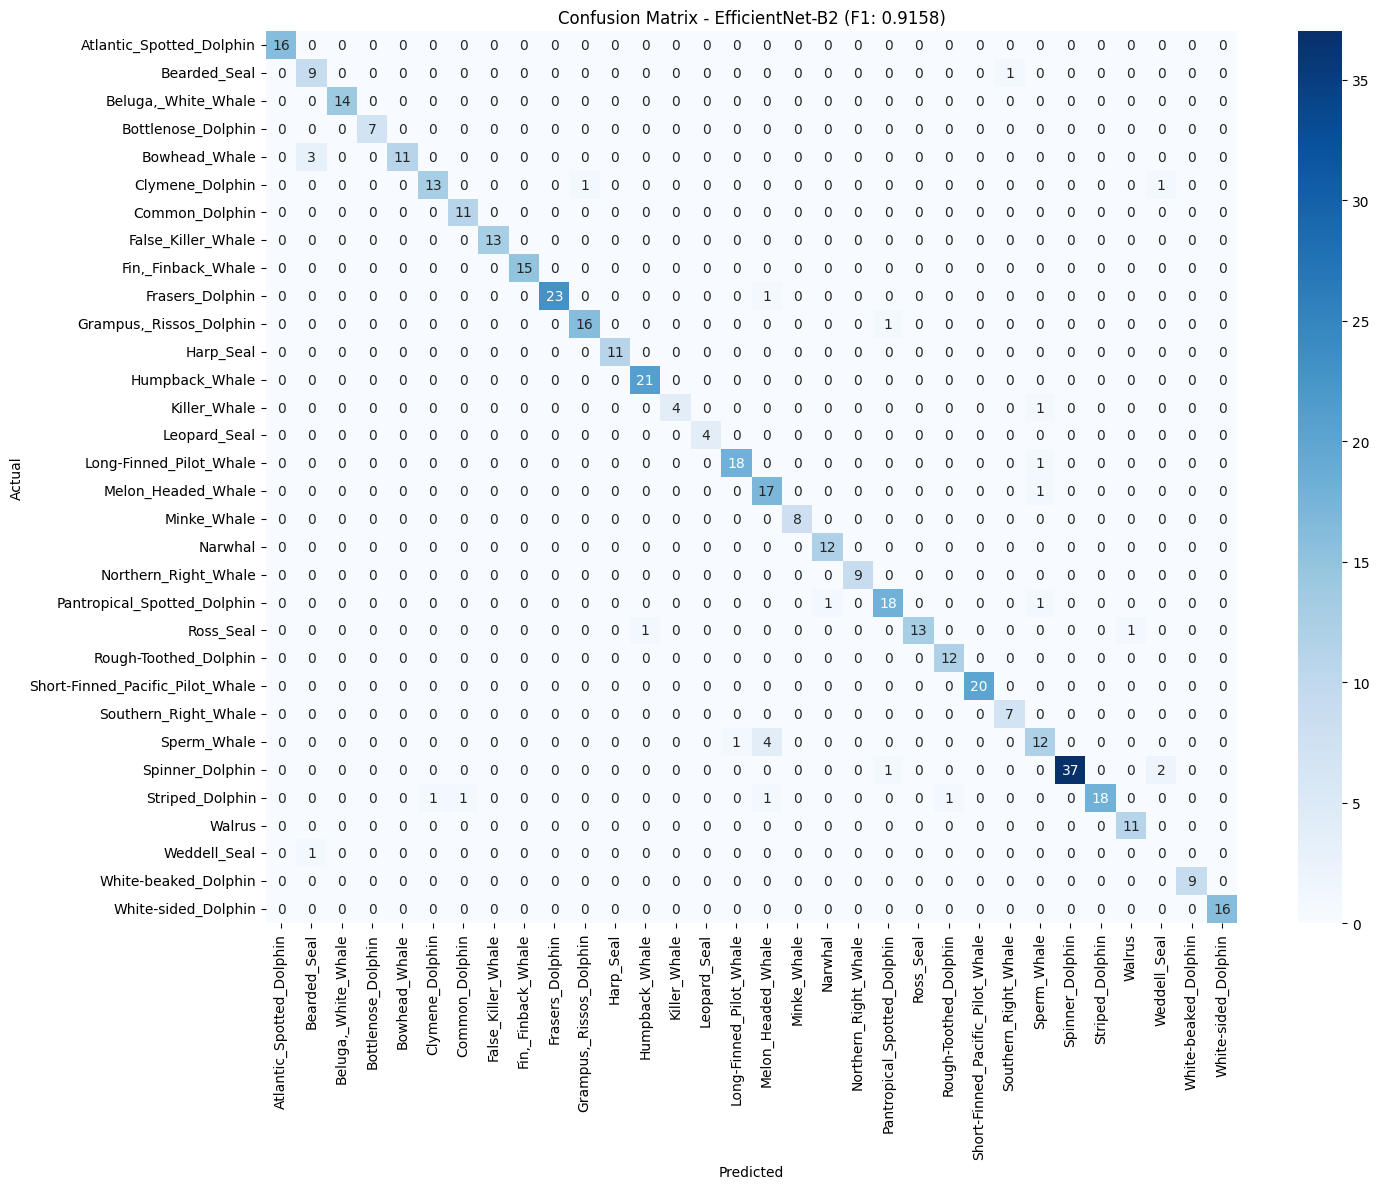


Detailed Classification Report:
                                  precision    recall  f1-score   support

        Atlantic_Spotted_Dolphin       1.00      1.00      1.00        16
                    Bearded_Seal       0.69      0.90      0.78        10
             Beluga,_White_Whale       1.00      1.00      1.00        14
              Bottlenose_Dolphin       1.00      1.00      1.00         7
                   Bowhead_Whale       1.00      0.79      0.88        14
                 Clymene_Dolphin       0.93      0.87      0.90        15
                  Common_Dolphin       0.92      1.00      0.96        11
              False_Killer_Whale       1.00      1.00      1.00        13
              Fin,_Finback_Whale       1.00      1.00      1.00        15
                 Frasers_Dolphin       1.00      0.96      0.98        24
         Grampus,_Rissos_Dolphin       0.94      0.94      0.94        17
                       Harp_Seal       1.00      1.00      1.00        11
    

In [6]:
# ==========================================
# 6. EVALUATION VISUALIZATION
# ==========================================
plt.figure(figsize=(15, 12))
cm = confusion_matrix(best_targets, best_preds)
# Normalize CM for clearer view
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title(f"Confusion Matrix - EfficientNet-B2 (F1: {best_f1:.4f})")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("\nDetailed Classification Report:")
print(classification_report(best_targets, best_preds, target_names=classes))

In [7]:
# ==========================================
# 7. FINAL SUBMISSION (TTA INCLUDED)
# ==========================================
# Kita pakai Test Time Augmentation sederhana: Center Crop
print("\n🚀 Generating Final Submission...")

class TestDataset(Dataset):
    def __init__(self, file_paths):
        self.file_paths = file_paths
        self.mel_spec = T.MelSpectrogram(sample_rate=CFG['sample_rate'], n_fft=CFG['n_fft'], hop_length=CFG['hop_length'], n_mels=CFG['n_mels'], f_min=CFG['f_min'], f_max=CFG['f_max'])
        self.to_db = T.AmplitudeToDB()

    def __len__(self): return len(self.file_paths)

    def __getitem__(self, idx):
        path = self.file_paths[idx]
        filename = os.path.basename(path)
        waveform, sr = torchaudio.load(path)
        if sr != CFG['sample_rate']: waveform = T.Resample(sr, CFG['sample_rate'])(waveform)
        
        # Loop Padding
        target_len = CFG['sample_rate'] * CFG['duration']
        if waveform.shape[1] < target_len:
            repeat = (target_len // waveform.shape[1]) + 1
            waveform = waveform.repeat(1, repeat)[:, :target_len]
        else:
            # Center Crop for Inference
            start = (waveform.shape[1] - target_len) // 2
            waveform = waveform[:, start:start+target_len]

        spec = self.mel_spec(waveform)
        spec = self.to_db(spec)
        spec = (spec - spec.min()) / (spec.max() - spec.min() + 1e-6) # Norm
        spec = torch.nn.functional.interpolate(spec.unsqueeze(0), size=(CFG['image_size'], CFG['image_size']), mode='bilinear', align_corners=False).squeeze(0)
        spec = spec.expand(3, -1, -1)
        return spec, filename

test_folder = os.path.join(CFG['root_dir'], 'test')
test_files = [os.path.join(test_folder, f) for f in os.listdir(test_folder) if f.endswith('.wav')]
test_ds = TestDataset(test_files)
test_loader = DataLoader(test_ds, batch_size=CFG['batch_size'], shuffle=False, num_workers=2)

model.load_state_dict(torch.load("best_model_efficientnet_b2.pth"))
model.eval()

final_preds = []
final_files = []

with torch.no_grad():
    for x, fnames in tqdm(test_loader):
        x = x.to(CFG['device'])
        outputs = model(x)
        preds = torch.argmax(outputs, dim=1)
        final_preds.extend(preds.cpu().numpy())
        final_files.extend(fnames)

sub_df = pd.DataFrame({'audio': final_files, 'species': [id2label[p] for p in final_preds]})
sub_df.to_csv('submission_effnet_b2.csv', index=False)
print("✅ Submission Saved!")


🚀 Generating Final Submission...


  0%|          | 0/22 [00:00<?, ?it/s]

✅ Submission Saved!
